# 실습04 · 클래스 불균형 (Class weight vs Sampler)

**목표:** train 6:2:1 불균형에서 손실 가중치와 재추출을 **별개 후보**로 두고, **같은 seed·epoch**에서 기준선과 비교한다. minority Recall과 과적합 징후를 수치로 해석한다.

**기능:**
1. train·valid 클래스 분포와 클래스 가중치를 계산한다.
2. none / weight / sampler 세 후보를 학습한다(TODO D04).
3. 세 후보의 비교 조건이 balance 하나만 다른지 확인한다.
4. history의 draw 열로 sampler가 실제로 뽑은 클래스 수를 확인한다.
5. minority Recall 해석: Recall이 같을 때 클래스별 손실·최소 정답 확률로 차이를 본다.
6. 과적합 징후 점검: best epoch 위치, valid loss 곡선, 비가중 train·valid 손실 차이.
7. Accuracy가 높아도 소수 클래스 Recall이 0일 수 있는 예를 계산한다.

> 입력: `../data/` · 결과: `outputs_notebook/` · 요약보고서: `실습04_불균형_요약보고서.md` (2.4절, 3.5~3.6절)

In [1]:
# ============================================================
# 0. 라이브러리 및 경로 설정
# ============================================================

# 경로를 운영체제와 무관하게 다루는 Path 클래스
from pathlib import Path
# 모듈 검색 경로 추가
import sys
# 수치 배열 계산
import numpy as np
# 표 데이터 처리·CSV 저장
import pandas as pd
# PyTorch: 텐서·모델 학습
import torch

# BASE : 노트북이 있는 단원 폴더 (노트북은 이 폴더에서 실행)
BASE = Path.cwd()
# 제공 모듈(../day14_vision/engine.py, models.py, explain.py) import 경로 추가
sys.path.insert(0, str(BASE.parent / "day14_vision"))

# DATA : 03_심화/data (원본 입력, 수정하지 않음)
# OUT  : 노트북 결과 저장 폴더 (main.py의 outputs/와 분리)
DATA = BASE.parent / "data"
OUT = BASE / "outputs_notebook"
OUT.mkdir(exist_ok=True)

# CPU 1-thread 고정 -> 실행마다 같은 결과
torch.set_num_threads(1)
print("DATA:", DATA.resolve())
print("OUT :", OUT.resolve())

DATA: /mnt/attach/project-files/20261105_day14/03_심화/data
OUT : /mnt/attach/project-files/20261105_day14/03_심화/실습04_불균형/outputs_notebook


## 1단계 · 분포와 클래스 가중치

In [2]:
# 제공 데이터셋 생성 함수
from engine import datasets

train, valid = datasets(DATA)
counts = torch.bincount(torch.tensor(train.targets), minlength=3).float()
print("class_to_idx:", train.class_to_idx)
print("train 개수:", counts.tolist(), "/ valid 개수:", torch.bincount(torch.tensor(valid.targets)).tolist())

# 역빈도 가중치를 평균 1로 정규화 -> [0.3, 0.9, 1.8]
w = 1 / counts
print("class weight:", (w / w.mean()).round(decimals=3).tolist())

class_to_idx: {'circle': 0, 'square': 1, 'triangle': 2}
train 개수: [120.0, 40.0, 20.0] / valid 개수: [30, 30, 30]
class weight: [0.30000001192092896, 0.8999999761581421, 1.7999999523162842]


## 2단계 · 세 후보 학습 (TODO D04)
뒤 단계에서 최종 모델을 다시 평가하려고 모델도 `models`에 보관한다.

In [3]:
# 제공 학습 골격
from engine import experiment

# TODO D04 정답 : 세 방법을 독립 후보로 (동시 적용 안 함)
methods = ["none", "weight", "sampler"]

rows, histories, models = [], {}, {}
for method in methods:
    # balance=method : 불균형 대응 방식 / epochs=8 : 같은 예산 (seed는 기본값 14로 동일)
    model, summary, history, _ = experiment(DATA, balance=method, epochs=8)
    rows.append(summary)
    histories[method] = history
    # models : best epoch 가중치가 복원된 최종 모델
    models[method] = model
    history.to_csv(OUT / f"{method}_history.csv", index=False)

result = pd.DataFrame(rows)
result.to_csv(OUT / "imbalance_comparison.csv", index=False)
print(result[["balance", "accuracy", "macro_f1", "triangle_recall"]].round(4).to_string(index=False))
print("sampler는 train만 재추출합니다. valid는 원래 분포 그대로입니다.")

balance  accuracy  macro_f1  triangle_recall
   none       1.0       1.0              1.0
 weight       1.0       1.0              1.0
sampler       1.0       1.0              1.0
sampler는 train만 재추출합니다. valid는 원래 분포 그대로입니다.


## 3단계 · 비교 포인트: 같은 seed·epoch인가
두 방법의 차이를 balance 하나로 설명하려면 나머지 조건이 같아야 한다.
- 같은 것: seed 14, epoch 8, epoch당 180장, head 전략(771개), AdamW·학습률, BN 통계 고정, 비가중 valid 평가
- 다른 것: weight는 **손실 가중치**, sampler는 **추출 확률**
- 주의: weight의 `train_objective`는 가중 손실이라 다른 후보와 같은 척도가 아니다. sampler는 같은 seed라도 매 epoch 들어가는 이미지가 다르다.

In [4]:
# 비교표에서 balance 외 조건 열이 모두 같은지 확인
same_cols = ["strategy", "epochs", "trainable", "best_epoch", "source"]
print(result[["balance"] + same_cols].to_string(index=False))
print("balance 외 조건 동일:", all(result[c].nunique() == 1 for c in ["strategy", "epochs", "trainable", "source"]))

balance strategy  epochs  trainable  best_epoch           source
   none     head       8        771           8 synthetic_source
 weight     head       8        771           8 synthetic_source
sampler     head       8        771           8 synthetic_source
balance 외 조건 동일: True


## 4단계 · sampler가 실제로 뽑은 클래스 수

In [5]:
# draw_* : epoch마다 학습에 들어간 클래스별 이미지 수
for method, h in histories.items():
    total = h[["draw_circle", "draw_square", "draw_triangle"]].sum().tolist()
    print(f"{method:8s} 1 epoch:", h.loc[0, ["draw_circle", "draw_square", "draw_triangle"]].tolist(), "/ 8 epoch 누적:", total)

# triangle 1장당 평균 학습 횟수 = 누적 triangle draw / 20장
print("triangle 1장당 학습 횟수:", {m: round(h.draw_triangle.sum() / 20, 1) for m, h in histories.items()})

none     1 epoch: [120, 40, 20] / 8 epoch 누적: [960, 320, 160]
weight   1 epoch: [120, 40, 20] / 8 epoch 누적: [960, 320, 160]
sampler  1 epoch: [57, 60, 63] / 8 epoch 누적: [484, 469, 487]
triangle 1장당 학습 횟수: {'none': np.float64(8.0), 'weight': np.float64(8.0), 'sampler': np.float64(24.4)}


## 5단계 · 최종 모델을 train·valid에 비가중으로 다시 평가
같은 척도로 비교하려고 train 180장도 섞지 않고 비가중 손실로 평가한다.
- 클래스별 손실 = 그 클래스 이미지들의 −log(정답 확률) 평균
- 최소 정답 확률 = 그 클래스에서 가장 애매하게 맞힌 이미지의 정답 확률

In [6]:
# 제공 평가 함수 (비가중 손실·지표)
from engine import evaluate
# 순서를 섞지 않고 배치 공급
from torch.utils.data import DataLoader

check = []
for m in methods:
    ts, ty, tp = evaluate(models[m], DataLoader(train, batch_size=32, shuffle=False))
    vs, vy, vp = evaluate(models[m], DataLoader(valid, batch_size=32, shuffle=False))
    # 기록
    # - train_loss_unweighted : train 비가중 평균 손실
    # - gap_valid_minus_train : valid - train (클수록 일반화 차이 큼)
    r = {"balance": m, "train_loss_unweighted": ts["loss"], "valid_loss": vs["loss"],
         "gap_valid_minus_train": vs["loss"] - ts["loss"], "train_macro_f1": ts["macro_f1"], "valid_macro_f1": vs["macro_f1"]}
    for c, n in enumerate(["circle", "square", "triangle"]):
        r[f"train_{n}_loss"] = float(-np.log(tp[ty == c, c]).mean())
        r[f"valid_{n}_loss"] = float(-np.log(vp[vy == c, c]).mean())
        r[f"valid_{n}_min_prob"] = float(vp[vy == c, c].min())
    check.append(r)

overfit = pd.DataFrame(check)
overfit.to_csv(OUT / "overfit_check.csv", index=False)
overfit.set_index("balance").T.round(4)

balance,none,weight,sampler
train_loss_unweighted,0.0064,0.0043,0.0054
valid_loss,0.0126,0.0066,0.0065
gap_valid_minus_train,0.0063,0.0022,0.0011
train_macro_f1,1.0000,1.0000,1.0000
valid_macro_f1,1.0000,1.0000,1.0000
train_circle_loss,0.0034,0.0041,0.0061
valid_circle_loss,0.0039,0.0053,0.0084
valid_circle_min_prob,0.9309,0.8948,0.8388
train_square_loss,0.0076,0.0040,0.0033
valid_square_loss,0.0163,0.0075,0.0045


## 6단계 · minority Recall 해석
세 후보 모두 triangle Recall 1.0이면 Recall로는 차이가 보이지 않는다. 클래스별 손실과 최소 정답 확률로 "얼마나 확실하게 맞혔는가"를 본다.

In [7]:
# 클래스(train 장수)별 valid Recall·손실·최소 정답 확률
table = []
for n, size in [("triangle", 20), ("square", 40), ("circle", 120)]:
    for m in methods:
        rec = result.set_index("balance").loc[m, f"{n}_recall"]
        o = overfit.set_index("balance").loc[m]
        table.append({"class": f"{n} ({size})", "balance": m, "recall": rec,
                      "valid_loss": round(o[f"valid_{n}_loss"], 4), "min_prob": round(o[f"valid_{n}_min_prob"], 3)})
pd.DataFrame(table).pivot(index="class", columns="balance", values=["recall", "valid_loss", "min_prob"])

recall                valid_loss                 min_prob  \
balance         none sampler weight       none sampler  weight     none   
class                                                                     
circle (120)     1.0     1.0    1.0     0.0039  0.0084  0.0053    0.931   
square (40)      1.0     1.0    1.0     0.0163  0.0045  0.0075    0.783   
triangle (20)    1.0     1.0    1.0     0.0178  0.0066  0.0068    0.762   

                              
balance       sampler weight  
class                         
circle (120)    0.839  0.895  
square (40)     0.941  0.907  
triangle (20)   0.895  0.882

**읽는 법**
- 보정 후보(weight·sampler)는 triangle·square 손실을 기준선의 절반 이하로 줄이고 최소 정답 확률을 올렸다.
- 대신 다수 클래스 circle의 손실은 늘고 최소 확률은 내려갔다 → 결정 경계를 다수 클래스 쪽으로 옮기는 **교환(trade-off)**.
- 지금은 모든 클래스가 여전히 정답이라 Recall이 변하지 않았지만, 더 어려운 데이터에서는 triangle Recall이 오르는 대신 circle Recall이 내려갈 수 있다.

## 7단계 · 과적합 징후 점검
과적합 = train은 계속 좋아지는데 valid는 멈추거나 나빠지는 현상. 세 가지로 본다.
1. valid loss 최소 epoch이 앞쪽에 있고 뒤에서 다시 오르는가
2. 최종 모델의 비가중 train·valid 손실 차이가 큰가
3. 반복 학습된 소수 클래스(triangle)에서 train·valid 차이가 벌어졌는가

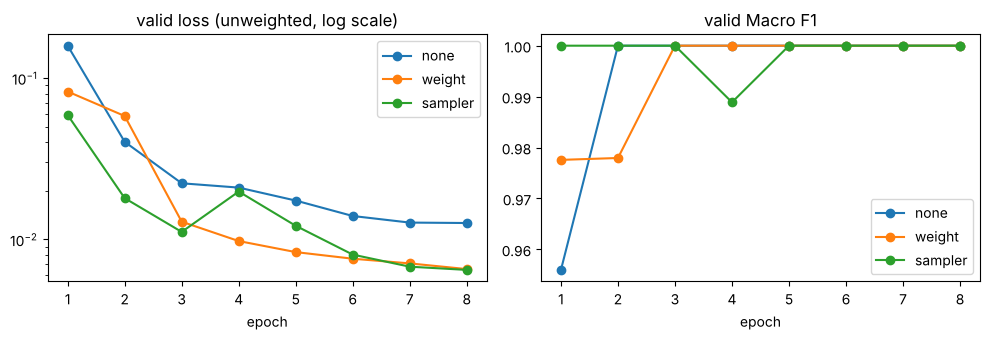

none     best epoch: 8 / valid loss 상승 epoch: []
weight   best epoch: 8 / valid loss 상승 epoch: []
sampler  best epoch: 8 / valid loss 상승 epoch: [4]


In [8]:
# 노트북 안에 곡선 표시
import matplotlib.pyplot as plt

# (1) epoch별 valid loss 곡선과 best epoch
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for m, h in histories.items():
    axes[0].plot(h.epoch, h.valid_loss, marker="o", label=m)
    axes[1].plot(h.epoch, h.valid_macro_f1, marker="o", label=m)
axes[0].set_title("valid loss (unweighted, log scale)")
axes[0].set_yscale("log")
axes[1].set_title("valid Macro F1")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()

for m, h in histories.items():
    best = int(h.loc[h.valid_loss.idxmin(), "epoch"])
    # 직전 epoch보다 valid loss가 오른 epoch 목록
    rises = h.epoch[h.valid_loss.diff() > 0].tolist()
    print(f"{m:8s} best epoch: {best} / valid loss 상승 epoch: {rises}")

In [9]:
# (2) 비가중 train·valid 손실 차이  (3) triangle train·valid 손실 차이
view = overfit[["balance", "train_loss_unweighted", "valid_loss", "gap_valid_minus_train", "train_triangle_loss", "valid_triangle_loss"]].copy()
view["triangle_gap"] = view.valid_triangle_loss - view.train_triangle_loss
view.round(4)

,balance,train_loss_unweighted,valid_loss,gap_valid_minus_train,train_triangle_loss,valid_triangle_loss,triangle_gap
0,none,0.0064,0.0126,0.0063,0.0219,0.0178,-0.0041
1,weight,0.0043,0.0066,0.0022,0.0060,0.0068,0.0008
2,sampler,0.0054,0.0065,0.0011,0.0052,0.0066,0.0014


**읽는 법**
- 세 후보 모두 best epoch가 마지막 epoch 8이면, 8 epoch 안에서 valid가 나빠지기 시작한 지점은 없다.
- sampler의 중간 상승(한 번 오르고 다음 epoch에 회복)은 복원 추출로 배치 구성이 바뀌는 데서 오는 흔들림으로 본다(가설).
- train·valid 차이가 0.01 미만으로 작고, triangle을 약 3배 반복한 sampler도 triangle 차이가 작으면 **과적합 징후 없음**으로 판단한다.
- 주의: epoch을 늘리거나 partial·full로 Backbone을 열면 반복 표본이 많은 sampler에서 먼저 차이가 벌어질 수 있다. 같은 점검을 다시 한다.

## 8단계 · Accuracy는 높고 minority Recall은 0인 예
valid가 train처럼 120/40/20이고 triangle만 전부 틀린다고 가정한 계산이다.

In [10]:
# 정확도·Macro F1·클래스별 Recall 계산 함수
from sklearn.metrics import accuracy_score, f1_score, recall_score

y_true = np.array([0] * 120 + [1] * 40 + [2] * 20)
# triangle 20장을 모두 circle로 예측, 나머지는 정답
y_pred = np.array([0] * 120 + [1] * 40 + [0] * 20)
print("accuracy:", round(accuracy_score(y_true, y_pred), 3))
print("triangle recall:", recall_score(y_true, y_pred, labels=[2], average="macro", zero_division=0))
print("macro F1:", round(f1_score(y_true, y_pred, labels=[0, 1, 2], average="macro", zero_division=0), 3))

accuracy: 0.889
triangle recall: 0.0
macro F1: 0.641


## 9단계 · expected·주석본 결과 대조

In [11]:
for name in ["imbalance_comparison.csv", "none_history.csv", "weight_history.csv", "sampler_history.csv"]:
    a = pd.read_csv(BASE / "expected" / name)
    b = pd.read_csv(OUT / name)
    num = [c for c in a.columns if pd.api.types.is_numeric_dtype(a[c]) and c != "seconds"]
    print(name, "일치:", np.allclose(a[num], b[num], atol=1e-6))

# overfit_check.csv는 expected가 없으므로 주석본 보조 측정 결과와 대조
ref = pd.read_csv(BASE.parent / "실습04_불균형_주석" / "outputs" / "overfit_check.csv")
num = [c for c in ref.columns if c != "balance"]
print("overfit_check.csv (주석본) 일치:", np.allclose(ref[num], overfit[num], atol=1e-6))

imbalance_comparison.csv 일치: True
none_history.csv 일치: True
weight_history.csv 일치: True
sampler_history.csv 일치: True
overfit_check.csv (주석본) 일치: True


## 정리
- **비교 조건:** weight와 sampler는 seed·epoch·학습 범위·학습률·BN 정책이 같고 balance만 다르다.
- **minority Recall:** triangle Recall은 셋 다 1.0이지만, 보정 후보는 소수 클래스 손실을 절반 이하로 줄이고 그만큼 circle 확신도가 내려갔다.
- **과적합 징후:** 8 epoch·Head만 학습 조건에서는 관찰되지 않았다(best epoch 8, train·valid 차이 작음).
- weight는 **손실 기여도**를 바꾸고(데이터 구성은 그대로 120/40/20), sampler는 **학습 표본 구성**을 바꾼다(약 60/60/60).
- 불균형 평가에서는 Accuracy 대신 Macro F1과 클래스별 Recall·손실을 함께 본다.